In [ ]:
import sys
sys.path.insert(0 , '../')
import src.data.loading as dt

df = dt.load_data()


In [3]:
df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [15]:
df.shape

(2000, 17)

In [16]:
df.describe()

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [4]:
df.columns

Index(['Student_ID', 'Age', 'Gender', 'Year_of_Study', 'Sleep_Hours',
       'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours',
       'Screen_Time_Hours', 'Physical_Activity', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate', 'Part_Time_Job', 'Diet_Quality',
       'Previous_Mental_Health_History', 'Mental_Health_Risk'],
      dtype='str')

In [5]:
df.isna().sum()

Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

i found values NaN in thoses Columns : 
- Sleep_Hours
- GPA
- Social_Media_Hours
- Financial_Stress
- Family_Support
- Diet_Quality

In [8]:
df.duplicated().sum()

np.int64(0)

i didn't found any duplicated 

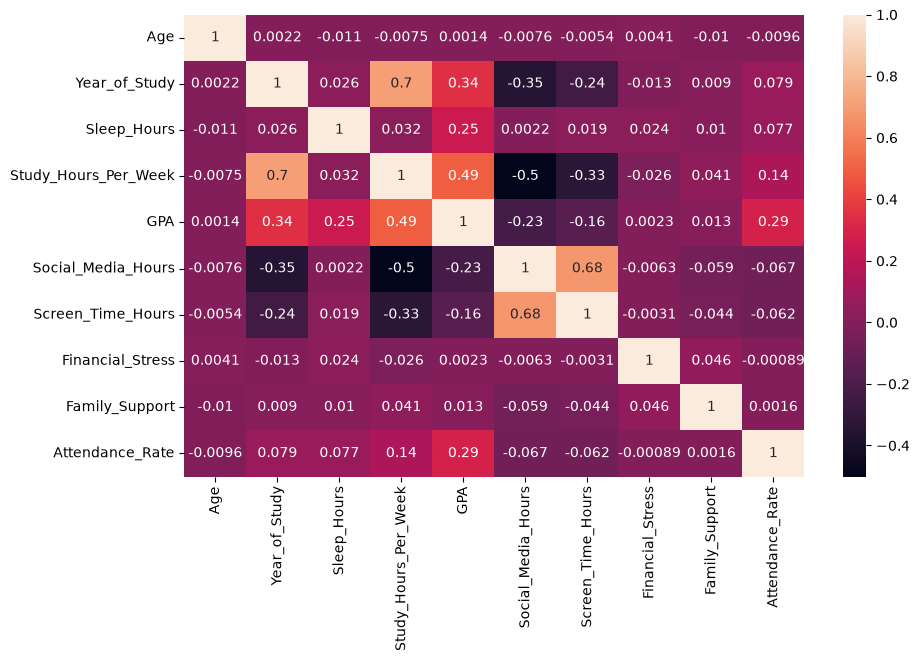

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
df.drop(columns="Student_ID")
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True) , annot=True)
plt.show()

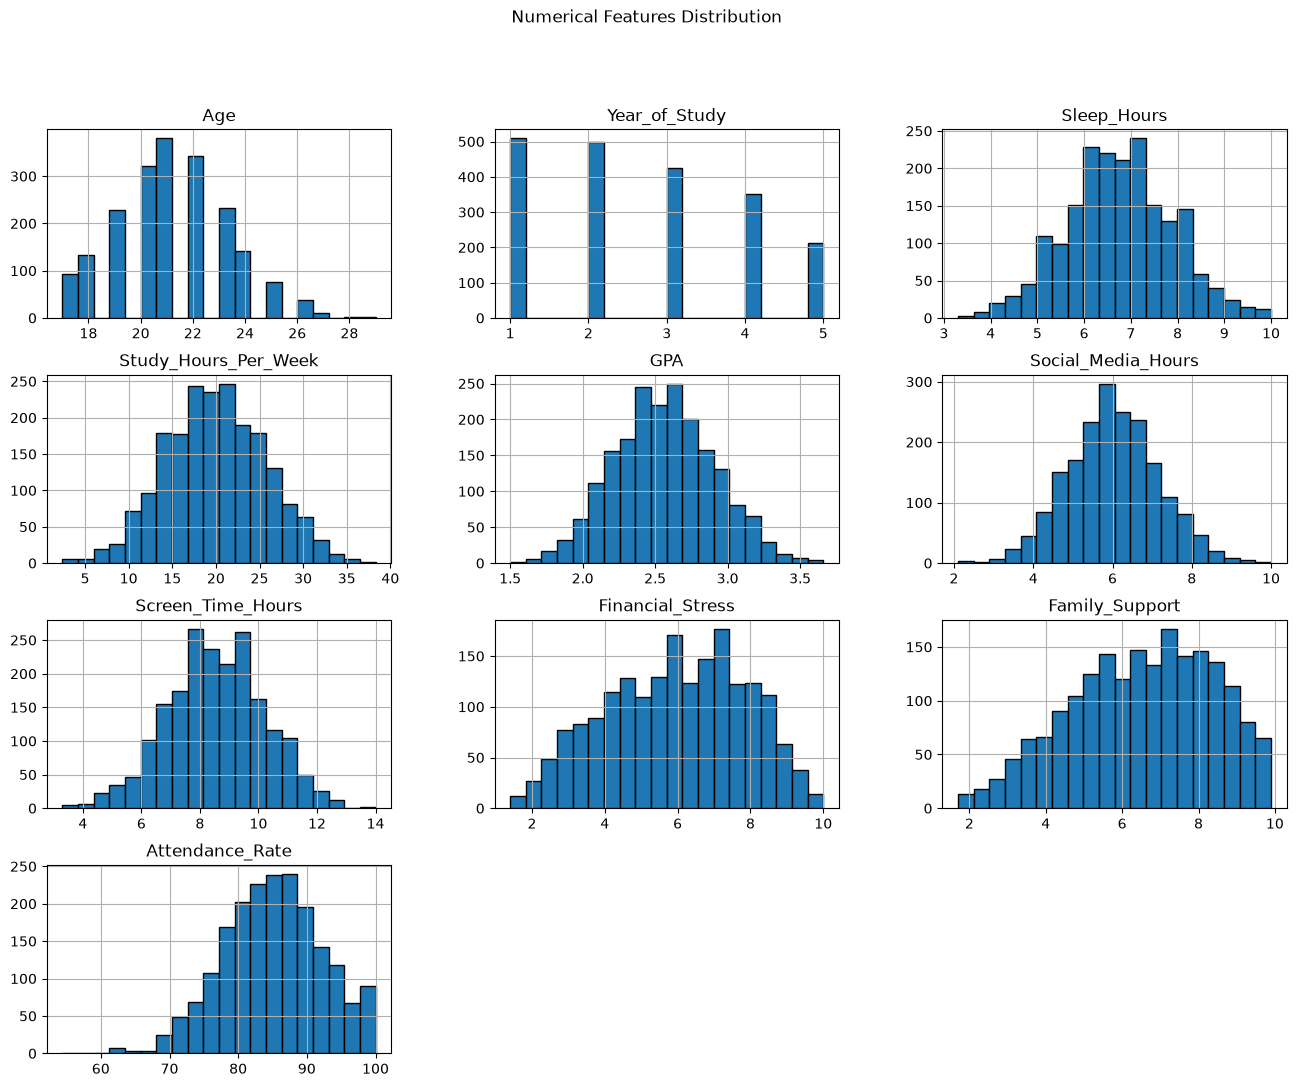

In [23]:
numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns

df[numerical_cols].hist(
    figsize=(16, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Numerical Features Distribution")
plt.show()

C:\Users\Youcode\AppData\Local\Temp\ipykernel_29524\3699550658.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns


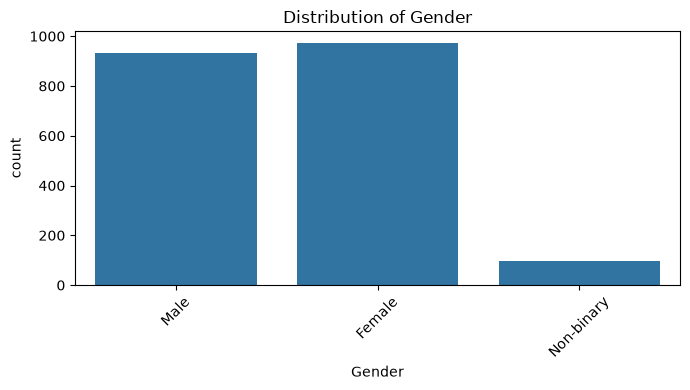

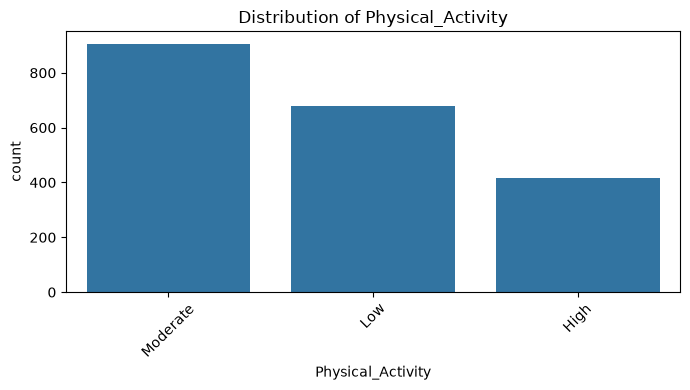

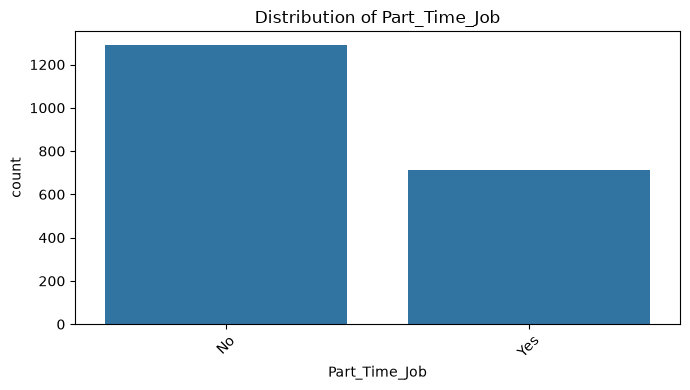

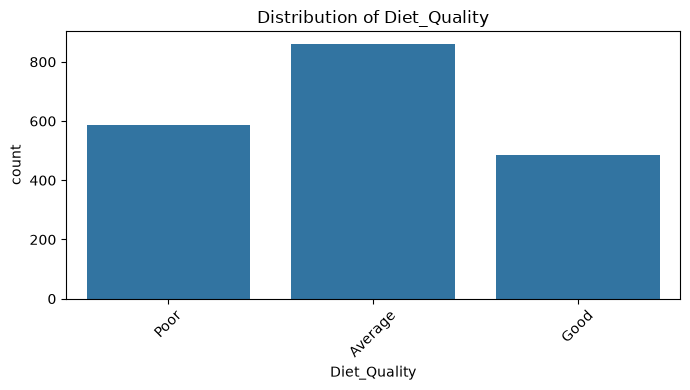

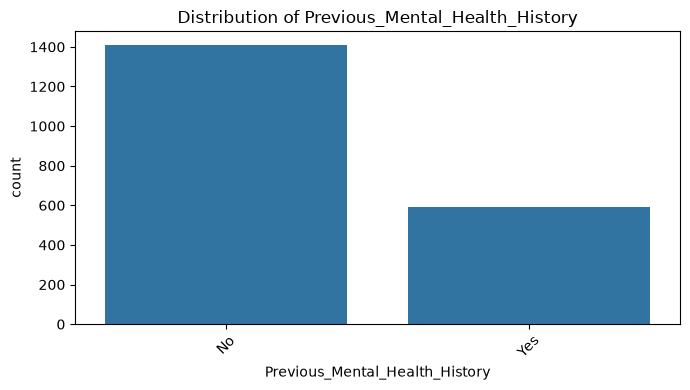

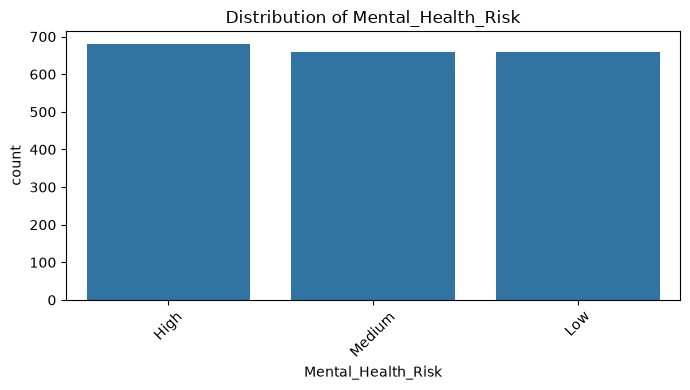

In [25]:
df = df.drop(columns="Student_ID")
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    plt.figure(figsize=(7, 4))

    sns.countplot(data=df, x=col)

    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [26]:
TARGET = "Mental_Health_Risk"

In [28]:
print(df[TARGET].value_counts())



Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


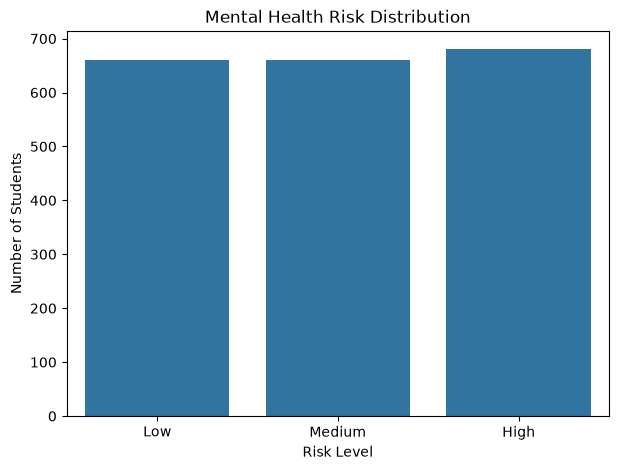

In [29]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x=TARGET,
    order=["Low", "Medium", "High"]
)

plt.title("Mental Health Risk Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Students")

plt.show()

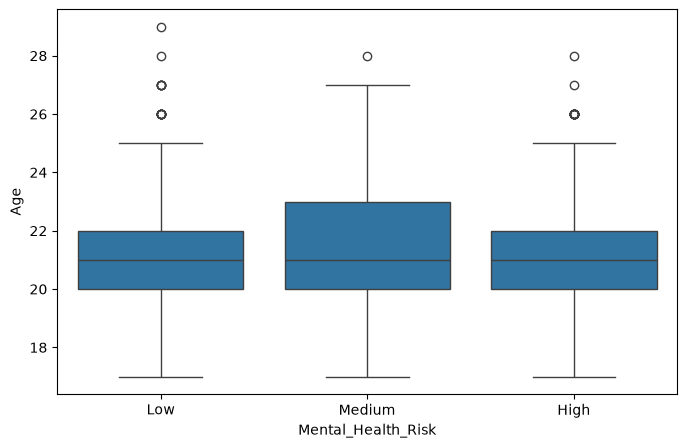

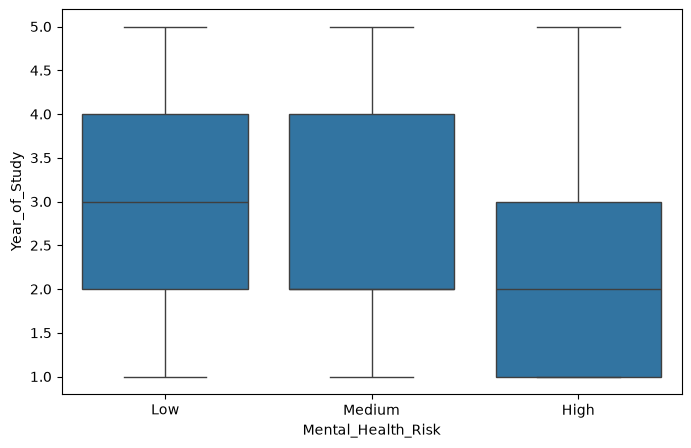

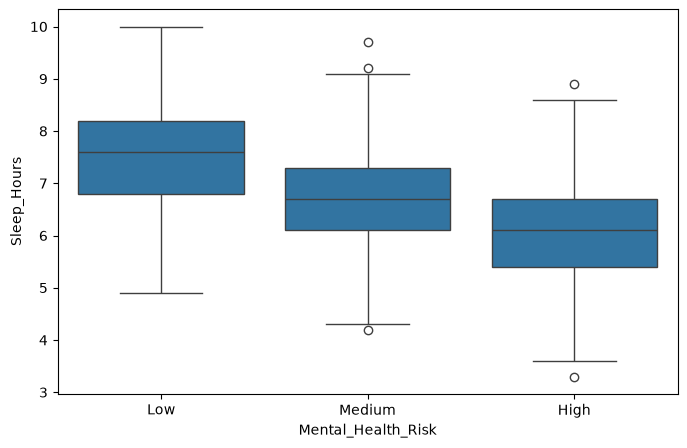

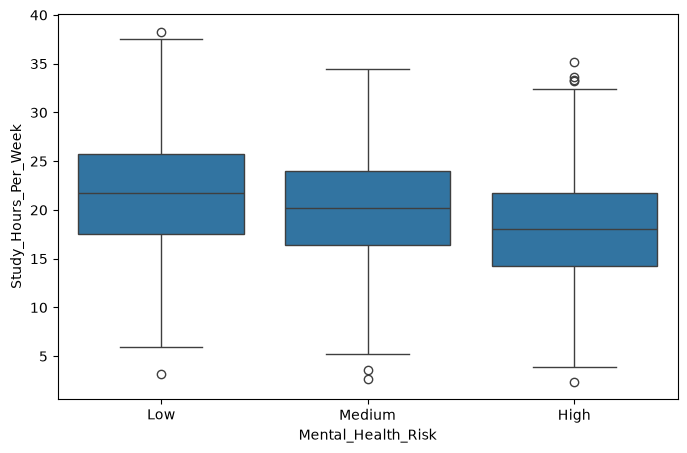

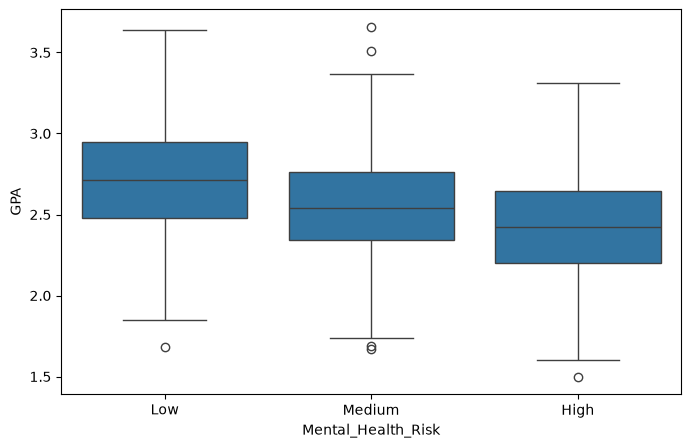

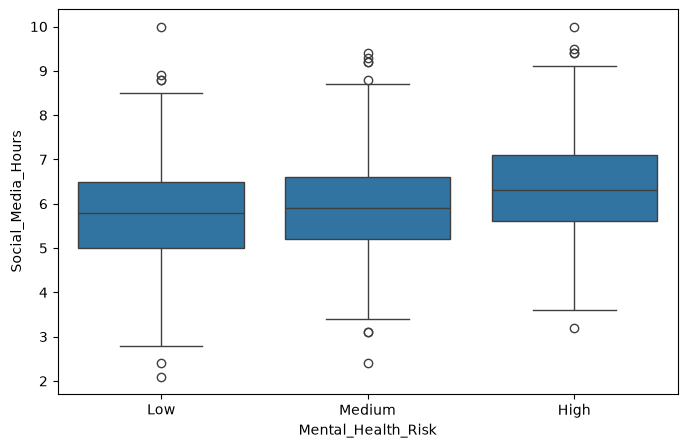

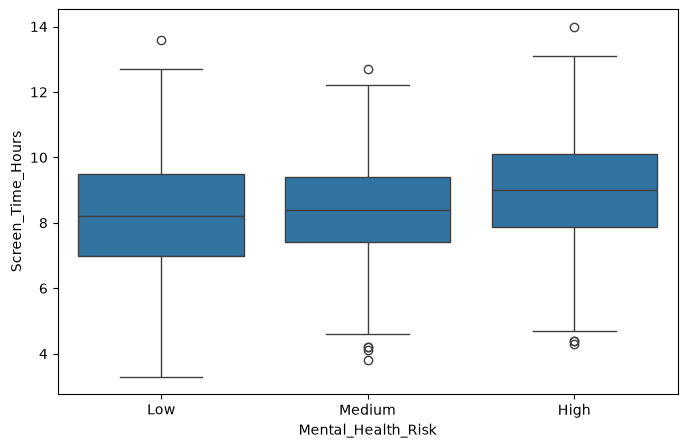

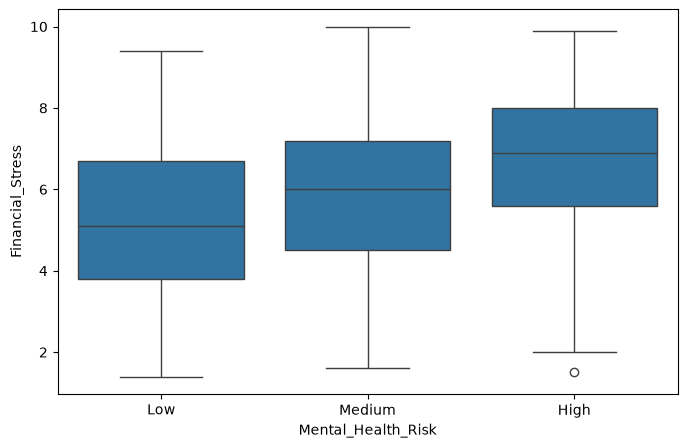

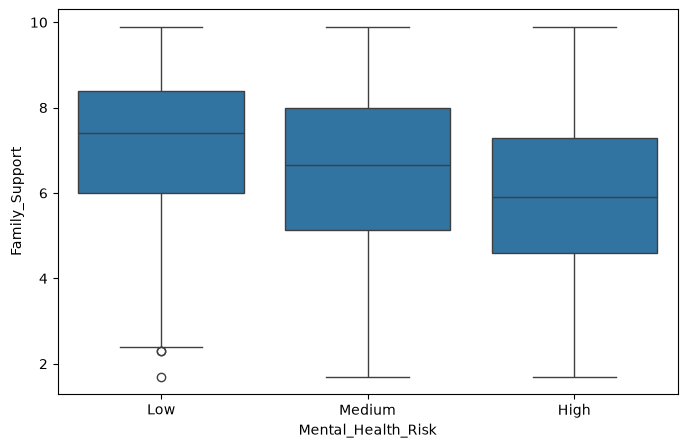

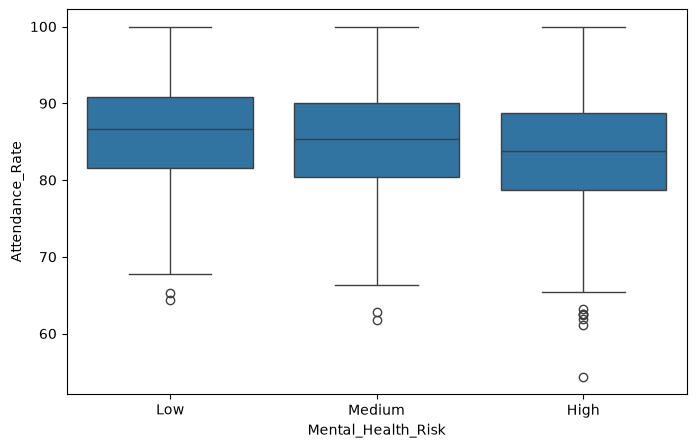

In [37]:
columns_box = df.select_dtypes(include="number").columns.tolist()
for column in columns_box : 

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x=TARGET,
        y=column,
        order=["Low", "Medium", "High"]
    )
    plt.show()